<a href="https://colab.research.google.com/github/vkrmgl/Wildlife-Capstone/blob/traffic-collision-eda/modeling210.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
"""
Cell 0 - Mount Google Drive.

"""

from google.colab import drive
import os

drive.mount('/content/drive')
PROJECT_DIR = "/content/drive/MyDrive/wvc_capstone"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Subfolders
for sub in ["dem_tiles", "slope_tiles", "data_oregon"]:
    os.makedirs(os.path.join(PROJECT_DIR, sub), exist_ok=True)

print(f"Google Drive mounted. Project folder ready at: {PROJECT_DIR}")
print("\nIMPORTANT: update the paths in your other scripts to point here")
print("instead of plain /content/ or relative paths, e.g.:")
print(f'  SEGMENTS_PATH = "{PROJECT_DIR}/oregon_road_segments.geojson"')
print(f'  DEM_TILES_FOLDER = "{PROJECT_DIR}/dem_tiles"')
print("\nAlso cd into it so relative paths work without editing every script:")
print(f'  %cd {PROJECT_DIR}')


Mounted at /content/drive
Google Drive mounted. Project folder ready at: /content/drive/MyDrive/wvc_capstone

IMPORTANT: update the paths in your other scripts to point here
instead of plain /content/ or relative paths, e.g.:
  SEGMENTS_PATH = "/content/drive/MyDrive/wvc_capstone/oregon_road_segments.geojson"
  DEM_TILES_FOLDER = "/content/drive/MyDrive/wvc_capstone/dem_tiles"

Also cd into it so relative paths work without editing every script:
  %cd /content/drive/MyDrive/wvc_capstone


In [2]:
"""
Cell 1

"""
%cd /content/drive/MyDrive/wvc_capstone

/content/drive/MyDrive/wvc_capstone


In [16]:

!pip -q install xgboost

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)
from xgboost import XGBRegressor

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score
)


In [5]:

# Load dataset
df = pd.read_parquet("/content/drive/MyDrive/or_segment_table.parquet")

# Display dataset dimensions
print(f"Total rows: {df.shape[0]:,}")
print(f"Total columns: {df.shape[1]:,}")

# List all column names and data types
print("\nAll Columns:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col} ({df[col].dtype})")

# Display all columns without truncation
pd.set_option('display.max_columns', None)

# Preview first 10 rows
display(df.head(10))

Total rows: 7,574
Total columns: 82

All Columns:
1. segment_id (object)
2. state (object)
3. route_id (object)
4. route (object)
5. mile (int64)
6. begin_mp (float64)
7. end_mp (float64)
8. length_mi (float64)
9. is_short (bool)
10. lat (float64)
11. lon (float64)
12. coll_all_2015_2020 (int64)
13. coll_all_2015_2020_per_yr (float64)
14. coll_deer_elk_2015_2020 (int64)
15. coll_deer_elk_2015_2020_per_yr (float64)
16. coll_deer_2015_2020 (int64)
17. coll_deer_2015_2020_per_yr (float64)
18. coll_elk_2015_2020 (int64)
19. coll_elk_2015_2020_per_yr (float64)
20. coll_moose_2015_2020 (int64)
21. coll_moose_2015_2020_per_yr (float64)
22. coll_all_2021_2025 (int64)
23. coll_all_2021_2025_per_yr (float64)
24. coll_deer_elk_2021_2025 (int64)
25. coll_deer_elk_2021_2025_per_yr (float64)
26. coll_deer_2021_2025 (int64)
27. coll_deer_2021_2025_per_yr (float64)
28. coll_elk_2021_2025 (int64)
29. coll_elk_2021_2025_per_yr (float64)
30. coll_moose_2021_2025 (int64)
31. coll_moose_2021_2025_per_yr (f

,segment_id,state,route_id,route,mile,begin_mp,end_mp,length_mi,is_short,lat,lon,coll_all_2015_2020,coll_all_2015_2020_per_yr,coll_deer_elk_2015_2020,coll_deer_elk_2015_2020_per_yr,coll_deer_2015_2020,coll_deer_2015_2020_per_yr,coll_elk_2015_2020,coll_elk_2015_2020_per_yr,coll_moose_2015_2020,coll_moose_2015_2020_per_yr,coll_all_2021_2025,coll_all_2021_2025_per_yr,coll_deer_elk_2021_2025,coll_deer_elk_2021_2025_per_yr,coll_deer_2021_2025,coll_deer_2021_2025_per_yr,coll_elk_2021_2025,coll_elk_2021_2025_per_yr,coll_moose_2021_2025,coll_moose_2021_2025_per_yr,elevation_mean_m,elevation_min_m,elevation_max_m,slope_mean_deg,slope_max_deg,terrain_pixels,ppt_month_mean_mm,ppt_month_min_mm,ppt_month_max_mm,ppt_annual_mm,tmean_c,tmean_month_min_c,tmean_month_max_c,tmean_winter_c,ppt_winter_month_mm,tmean_summer_c,ppt_summer_month_mm,weather_months,pop_density_per_km2,hpms_coverage,hpms_aadt,hpms_log_aadt,hpms_truck_share,hpms_lanes,hpms_speed_limit,hpms_rural_share,hpms_f_system,hpms_functional_class,hpms_access_control,nlcd_water,nlcd_developed,nlcd_barren,nlcd_forest,nlcd_shrub,nlcd_grass,nlcd_agriculture,nlcd_wetland,nlcd_dominant,nlcd_pixels,gbif_deer,gbif_elk,gbif_moose,gbif_bear,gbif_cougar,gbif_pronghorn,gbif_mt_goat,gbif_bighorn_sheep,gbif_owl,gbif_hawk,gbif_bald_eagle,gbif_golden_eagle
0,00100I00_0,OR,00100I00,001,0,0.0,1.0,1.0,False,42.012646,-122.614549,8,1.333333,8,1.333333,8,1.333333,0,0.0,0,0.0,3,0.6,3,0.6,3,0.6,0,0.0,0,0.0,1058.371538,1009.552612,1094.364380,8.000747,22.929638,221,43.468530,0.0,194.695007,521.622356,11.485346,-0.561000,24.987700,2.997117,87.852250,21.304917,9.066818,132,2.538899,1.0,15453.37,9.645582,0.368977,4.0,55.0,1.0,1.0,interstate,1.0,0.0,0.284722,0.0,0.020833,0.677083,0.017361,0.0,0.0,shrub,864,3,1,0,2,1,0,0,0,1,3,0,2
1,00100I00_1,OR,00100I00,001,1,1.0,2.0,1.0,False,42.025043,-122.605187,27,4.500000,27,4.500000,27,4.500000,0,0.0,0,0.0,23,4.6,23,4.6,23,4.6,0,0.0,0,0.0,1108.341004,1085.329712,1142.706299,7.855221,20.151308,219,46.605247,0.0,209.094002,559.262967,10.885319,-0.550000,24.155850,2.729640,93.569906,20.513264,10.287219,132,2.210078,1.0,15403.00,9.642318,0.369019,4.0,55.0,1.0,1.0,interstate,1.0,0.0,0.376471,0.0,0.009412,0.612941,0.001176,0.0,0.0,shrub,850,2,1,0,5,1,0,0,0,2,4,0,2
2,00100I00_2,OR,00100I00,001,2,2.0,3.0,1.0,False,42.037973,-122.598266,20,3.333333,20,3.333333,20,3.333333,0,0.0,0,0.0,4,0.8,4,0.8,4,0.8,0,0.0,0,0.0,1168.896682,1131.048828,1221.358887,11.971700,34.280299,221,51.020780,0.0,218.968994,612.249363,9.908674,-1.852000,22.785500,2.368223,101.228053,19.159039,11.468464,132,2.130930,1.0,15403.00,9.642318,0.369019,4.0,55.0,1.0,1.0,interstate,1.0,0.0,0.389286,0.0,0.253571,0.357143,0.000000,0.0,0.0,developed,840,2,1,0,6,1,0,0,0,3,4,0,2
3,00100I00_3,OR,00100I00,001,3,3.0,4.0,1.0,False,42.050024,-122.606648,9,1.500000,8,1.333333,8,1.333333,0,0.0,0,0.0,8,1.6,8,1.6,7,1.4,1,0.2,0,0.0,1257.820188,1205.338867,1310.928101,15.542857,35.398498,228,47.089160,0.0,213.047779,565.069917,10.814750,-0.550889,24.060745,2.685858,94.517080,20.431103,10.564945,132,2.039646,1.0,15403.00,9.642318,0.369019,4.0,55.0,1.0,1.0,interstate,1.0,0.0,0.296948,0.0,0.193662,0.507042,0.002347,0.0,0.0,shrub,852,1,0,0,6,0,0,0,0,3,3,0,1
4,00100I00_4,OR,00100I00,001,4,4.0,5.0,1.0,False,42.062585,-122.604861,4,0.666667,2,0.333333,2,0.333333,0,0.0,0,0.0,2,0.4,2,0.4,2,0.4,0,0.0,0,0.0,1303.300180,1250.532837,1352.215698,16.853235,45.464401,229,47.720030,0.0,219.116447,572.640356,10.869816,-0.497444,24.002089,2.747401,93.277359,20.491448,10.726711,132,2.153027,1.0,15403.00,9.642318,0.369019,4.0,55.0,1.0,1.0,interstate,1.0,0.0,0.245921,0.0,0.377622,0.376457,0.000000,0.0,0.0,forest,858,1,0,0,6,0,0,0,0,4,3,0,1
5,00100I00_5,OR,00100I00,001,5,5.0,6.0,1.0,False,42.075330,-122.604799,10,1.666667,8,1.333333,8,1.333333,0,0.0,0,0.0,3,0.6,3,0.6,3,0.6,0,0.0,0,0.0,1216.887338,1156.263672,1272.983521,14.287577,28.000449,241,49.987721,0.0,229.302668,599.852650,10.486371,-0.732000,23.366267,2.625499,96.279761,19.949946,11.260037,132,2

In [8]:
# Identify identifiers, location fields, and collision targets
id_cols = [
    'segment_id', 'state', 'route_id', 'route',
    'mile', 'begin_mp', 'end_mp', 'lat', 'lon'
]

target_cols = [
    col for col in df.columns
    if col.startswith('coll_')
]

# Potential predictive features
feature_cols = [
    col for col in df.columns
    if col not in id_cols + target_cols
]

# Display column counts
print("Total columns:", len(df.columns))
print("Identifier/location columns:", len(id_cols))
print("Collision target columns:", len(target_cols))
print("Potential predictive features:", len(feature_cols))

# List all identifier/location columns
print("\n========== IDENTIFIER/LOCATION COLUMNS ==========")
for i, col in enumerate(id_cols, 1):
    print(f"{i}. {col}")

# List all collision target columns
print("\n========== COLLISION TARGET COLUMNS ==========")
for i, col in enumerate(target_cols, 1):
    print(f"{i}. {col}")

# List all predictive features
print("\n========== POTENTIAL PREDICTIVE FEATURES ==========")
for i, col in enumerate(feature_cols, 1):
    print(f"{i}. {col}")

# Display predictive features with data types
print("\n========== FEATURE SUMMARY ==========")

feature_summary = pd.DataFrame({
    "Feature Name": feature_cols,
    "Data Type": df[feature_cols].dtypes.values
})

display(feature_summary)

Total columns: 82
Identifier/location columns: 9
Collision target columns: 20
Potential predictive features: 53

========== IDENTIFIER/LOCATION COLUMNS ==========
1. segment_id
2. state
3. route_id
4. route
5. mile
6. begin_mp
7. end_mp
8. lat
9. lon

========== COLLISION TARGET COLUMNS ==========
1. coll_all_2015_2020
2. coll_all_2015_2020_per_yr
3. coll_deer_elk_2015_2020
4. coll_deer_elk_2015_2020_per_yr
5. coll_deer_2015_2020
6. coll_deer_2015_2020_per_yr
7. coll_elk_2015_2020
8. coll_elk_2015_2020_per_yr
9. coll_moose_2015_2020
10. coll_moose_2015_2020_per_yr
11. coll_all_2021_2025
12. coll_all_2021_2025_per_yr
13. coll_deer_elk_2021_2025
14. coll_deer_elk_2021_2025_per_yr
15. coll_deer_2021_2025
16. coll_deer_2021_2025_per_yr
17. coll_elk_2021_2025
18. coll_elk_2021_2025_per_yr
19. coll_moose_2021_2025
20. coll_moose_2021_2025_per_yr

========== POTENTIAL PREDICTIVE FEATURES ==========
1. length_mi
2. is_short
3. elevation_mean_m
4. elevation_min_m
5. elevation_max_m
6. slope_mea

,Feature Name,Data Type
0,length_mi,float64
1,is_short,bool
2,elevation_mean_m,float64
3,elevation_min_m,float64
4,elevation_max_m,float64
5,slope_mean_deg,float64
6,slope_max_deg,float64
7,terrain_pixels,int64
8,ppt_month_mean_mm,float64
9,ppt_month_min_mm,float64


In [9]:
# Missing value analysis
missing_df = pd.DataFrame({
    "Column": df.columns,
    "Missing Count": df.isnull().sum().values,
    "Missing Percentage": (
        df.isnull().mean().values * 100
    ).round(2)
})

# Sort by highest missing percentage
missing_df = missing_df.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_df)

,Column,Missing Count,Missing Percentage
53,hpms_truck_share,34,0.45
52,hpms_log_aadt,34,0.45
51,hpms_aadt,34,0.45
2,route_id,0,0.00
4,mile,0,0.00
...,...,...,...
77,gbif_bighorn_sheep,0,0.00
78,gbif_owl,0,0.00
79,gbif_hawk,0,0.00
80,gbif_bald_eagle,0,0.00


In [10]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check for duplicate segment IDs
print("Duplicate segment IDs:", df['segment_id'].duplicated().sum())

# Check dataset dimensions
print("Dataset shape:", df.shape)

Duplicate rows: 0
Duplicate segment IDs: 0
Dataset shape: (7574, 82)


In [11]:
# Select numerical predictive features
numeric_features = df[feature_cols].select_dtypes(
    include=['int64', 'float64']
)

# Generate descriptive statistics
stats = numeric_features.describe().T

# Add skewness and missing-value counts
stats['skewness'] = numeric_features.skew()
stats['missing'] = numeric_features.isnull().sum()

# Display all statistics
display(stats.round(2))

,count,mean,std,min,25%,50%,75%,max,skewness,missing
length_mi,7574.0,0.97,0.14,0.01,1.00,1.00,1.00,1.00,-5.01,0
elevation_mean_m,7574.0,619.03,516.17,0.45,100.62,522.37,1106.46,1941.66,0.32,0
elevation_min_m,7574.0,603.87,514.84,-7.16,89.02,504.90,1085.81,1925.24,0.33,0
elevation_max_m,7574.0,638.04,516.65,0.59,120.18,548.46,1130.00,1956.19,0.31,0
slope_mean_deg,7574.0,5.90,5.45,0.01,1.75,4.02,8.54,33.97,1.43,0
slope_max_deg,7574.0,18.05,13.31,0.01,6.69,15.11,27.80,74.08,0.69,0
terrain_pixels,7574.0,222.90,34.31,9.00,220.00,229.00,236.00,482.00,-3.11,0
ppt_month_mean_mm,7574.0,72.21,55.27,15.83,26.15,48.51,99.58,360.39,1.19,0
ppt_month_min_mm,7574.0,0.13,0.53,0.00,0.00,0.00,0.00,5.33,5.44,0
ppt_month_max_mm,7574.0,303.70,234.31,58.14,97.03,207.58,456.92,1352.86,0.93,0


In [13]:
# Identify constant features
constant_features = [
    col for col in feature_cols
    if df[col].nunique(dropna=False) == 1
]

print("Constant features:", len(constant_features))

for col in constant_features:
    print(f"{col}: {df[col].iloc[0]}")


# Keep original dataset unchanged
df_original = df.copy()

# Create modeling feature list
model_features = [
    col for col in feature_cols
    if col not in constant_features
]

# Create modeling dataset
X = df[model_features].copy()

print("Original dataset:", df_original.shape)
print("Modeling features:", X.shape)

Constant features: 2
weather_months: 132
gbif_moose: 0
Original dataset: (7574, 82)
Modeling features: (7574, 51)


In [14]:
# Identify collision count columns (exclude annualized rates)
collision_cols = [
    col for col in target_cols
    if not col.endswith('_per_yr')
]

# Generate collision summary
collision_summary = pd.DataFrame({
    'Collision Type': collision_cols,
    'Total Collisions': df[collision_cols].sum().values,
    'Mean': df[collision_cols].mean().values,
    'Median': df[collision_cols].median().values,
    'Maximum': df[collision_cols].max().values,
    'Zero Count': (df[collision_cols] == 0).sum().values,
    'Zero Percentage': (
        (df[collision_cols] == 0).mean().values * 100
    ).round(2)
})

display(collision_summary)

,Collision Type,Total Collisions,Mean,Median,Maximum,Zero Count,Zero Percentage
0,coll_all_2015_2020,42644,5.630314,2.0,113,1916,25.30
1,coll_deer_elk_2015_2020,37865,4.999340,2.0,112,2290,30.24
2,coll_deer_2015_2020,36138,4.771323,2.0,112,2391,31.57
3,coll_elk_2015_2020,1727,0.228017,0.0,19,6694,88.38
4,coll_moose_2015_2020,0,0.000000,0.0,0,7574,100.00
5,coll_all_2021_2025,28264,3.731714,2.0,73,2305,30.43
6,coll_deer_elk_2021_2025,25429,3.357407,1.0,73,2641,34.87
7,coll_deer_2021_2025,24209,3.196330,1.0,73,2772,36.60
8,coll_elk_2021_2025,1220,0.161077,0.0,11,6829,90.16
9,coll_moose_2021_2025,0,0.000000,0.0,0,7574,100.00


In [26]:
# Historical collision occurrence
historical = df['coll_deer_elk_2015_2020'] > 0

# Future collision occurrence
future = df['coll_deer_elk_2021_2025'] > 0

# Compare both periods
comparison = pd.crosstab(
    historical,
    future,
    rownames=['2015–2020 Collisions'],
    colnames=['2021–2025 Collisions']
)

comparison.index = ['No collisions', 'Collisions']
comparison.columns = ['No collisions', 'Collisions']

display(comparison)

,No collisions,Collisions
No collisions,1596,694
Collisions,1045,4239


In [17]:

# Preserve original dataset
df_original = df.copy()

# Exclude constant features
model_features = [
    col for col in feature_cols
    if col not in ['weather_months', 'gbif_moose']
]

X = df[model_features].copy()

# Classification: 1 = at least one collision, 0 = none
y_class = (
    df['coll_deer_elk_2021_2025'] > 0
).astype(int)

# Regression: annual collision rate
y_reg = df['coll_deer_elk_2021_2025_per_yr'].copy()

# Separate categorical and numeric columns
cat_cols = X.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

num_cols = X.select_dtypes(
    include=['number', 'bool']
).columns.tolist()

# Preprocessing inside each CV fold
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, num_cols),
    ('categorical', categorical_pipeline, cat_cols)
])

print("Modeling rows:", len(X))
print("Predictive features:", X.shape[1])
print("Categorical features:", cat_cols)
print("Collision occurrence rate:", round(y_class.mean(), 3))


Modeling rows: 7574
Predictive features: 51
Categorical features: ['hpms_functional_class', 'nlcd_dominant']
Collision occurrence rate: 0.651


In [18]:

classification_models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    'Random Forest Classifier': RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
}

cv_class = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

class_results = []

for name, estimator in classification_models.items():
    print(f"Running {name}...")

    pipeline = Pipeline([
        ('preprocess', preprocessor),
        ('model', estimator)
    ])

    probabilities = cross_val_predict(
        pipeline, X, y_class,
        cv=cv_class,
        method='predict_proba',
        n_jobs=1
    )[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    class_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_class, predictions),
        'Precision': precision_score(
            y_class, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_class, predictions, zero_division=0
        ),
        'F1': f1_score(y_class, predictions),
        'ROC-AUC': roc_auc_score(y_class, probabilities)
    })

classification_results = pd.DataFrame(class_results)
display(classification_results.round(3))


Running Logistic Regression...
Running Random Forest Classifier...


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.742,0.769,0.863,0.813,0.790
1,Random Forest Classifier,0.785,0.813,0.870,0.841,0.858


In [19]:

regression_models = {
    'Random Forest Regressor': RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),
    'XGBoost Regressor': XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=4
    )
}

cv_reg = KFold(
    n_splits=5, shuffle=True, random_state=42
)

reg_results = {}
reg_predictions = {}

for name, estimator in regression_models.items():
    print(f"Running {name}...")

    pipeline = Pipeline([
        ('preprocess', preprocessor),
        ('model', estimator)
    ])

    predictions = cross_val_predict(
        pipeline, X, y_reg,
        cv=cv_reg,
        n_jobs=1
    )

    predictions = np.maximum(predictions, 0)
    reg_predictions[name] = predictions

    reg_results[name] = {
        'MAE': mean_absolute_error(y_reg, predictions),
        'RMSE': np.sqrt(
            mean_squared_error(y_reg, predictions)
        ),
        'R2': r2_score(y_reg, predictions)
    }

regression_results = pd.DataFrame.from_dict(
    reg_results, orient='index'
).reset_index().rename(columns={'index': 'Model'})

display(regression_results.round(3))


Running Random Forest Regressor...
Running XGBoost Regressor...


,Model,MAE,RMSE,R2
0,Random Forest Regressor,0.421,0.774,0.543
1,XGBoost Regressor,0.431,0.774,0.542


In [20]:

from scipy.stats import spearmanr

def capture_at_k(y_true, scores, lengths, k=10):
    temp = pd.DataFrame({
        'actual': np.asarray(y_true),
        'score': np.asarray(scores),
        'length': np.asarray(lengths)
    }).sort_values('score', ascending=False)

    cutoff = temp['length'].sum() * k / 100
    selected = temp['length'].cumsum() <= cutoff

    # Include segment crossing the mileage threshold
    n_selected = min(selected.sum() + 1, len(temp))

    captured = temp.iloc[:n_selected]['actual'].sum()
    total = temp['actual'].sum()

    return captured / total if total > 0 else np.nan

ranking_results = []

scores = {
    'B0 Historical Baseline':
        df['coll_deer_elk_2015_2020_per_yr'].values,
    **reg_predictions
}

for name, pred in scores.items():
    ranking_results.append({
        'Model': name,
        'Capture@1%': capture_at_k(
            y_reg, pred, df['length_mi'], 1
        ),
        'Capture@5%': capture_at_k(
            y_reg, pred, df['length_mi'], 5
        ),
        'Capture@10%': capture_at_k(
            y_reg, pred, df['length_mi'], 10
        ),
        'Spearman': spearmanr(pred, y_reg).statistic
    })

ranking_df = pd.DataFrame(ranking_results)
display(ranking_df.round(3))


,Model,Capture@1%,Capture@5%,Capture@10%,Spearman
0,B0 Historical Baseline,0.095,0.284,0.431,0.755
1,Random Forest Regressor,0.076,0.252,0.400,0.730
2,XGBoost Regressor,0.079,0.259,0.385,0.712


In [22]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import spearmanr

# Keep original dataset unchanged
baseline_df = df.copy()

# Historical annual collision rate (2015–2020)
baseline_df['predicted_risk'] = (
    baseline_df['coll_deer_elk_2015_2020_per_yr']
)

# Actual annual collision rate (2021–2025)
baseline_df['actual_risk'] = (
    baseline_df['coll_deer_elk_2021_2025_per_yr']
)

display(baseline_df[
    ['segment_id', 'predicted_risk', 'actual_risk']
].head(10))

,segment_id,predicted_risk,actual_risk
0,00100I00_0,1.333333,0.6
1,00100I00_1,4.500000,4.6
2,00100I00_2,3.333333,0.8
3,00100I00_3,1.333333,1.6
4,00100I00_4,0.333333,0.4
5,00100I00_5,1.333333,0.6
6,00100I00_6,2.166667,3.2
7,00100I00_7,1.333333,1.6
8,00100I00_8,0.833333,1.4
9,00100I00_9,1.833333,0.4


In [23]:
# Define actual and predicted values
y_true = baseline_df['actual_risk']
y_pred = baseline_df['predicted_risk']

# Calculate metrics
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)
spearman = spearmanr(y_true, y_pred).statistic

print("========== BASELINE MODEL (B0) ==========")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")
print(f"Spearman Correlation: {spearman:.4f}")

========== BASELINE MODEL (B0) ==========
MAE: 0.4248
RMSE: 0.7583
R²: 0.5603
Spearman Correlation: 0.7554


In [24]:
def capture_at_k(data, k):
    ranked = data.sort_values(
        'predicted_risk', ascending=False
    ).copy()

    total_miles = ranked['length_mi'].sum()
    target_miles = total_miles * (k / 100)

    # Include the portion of each segment within the mileage budget
    remaining = (
        target_miles -
        ranked['length_mi'].cumsum().shift(fill_value=0)
    )

    selected_miles = remaining.clip(lower=0)
    selected_miles = np.minimum(
        selected_miles, ranked['length_mi']
    )

    fraction_selected = (
        selected_miles / ranked['length_mi']
    )

    captured = (
        ranked['actual_risk'] * fraction_selected
    ).sum()

    total = ranked['actual_risk'].sum()

    return captured / total if total > 0 else np.nan


print("========== BASELINE CAPTURE@K ==========")

for k in [1, 5, 10, 20]:
    score = capture_at_k(baseline_df, k)
    print(f"Capture@{k}%: {score:.2%}")

========== BASELINE CAPTURE@K ==========
Capture@1%: 9.45%
Capture@5%: 28.38%
Capture@10%: 43.09%
Capture@20%: 62.26%


In [25]:
# Add historical collision information to the predictors
X_combined = X.copy()

X_combined['historical_collision_rate'] = (
    df['coll_deer_elk_2015_2020_per_yr']
)

# Build preprocessing for combined features
combined_num_cols = X_combined.select_dtypes(
    include=['number', 'bool']
).columns.tolist()

combined_cat_cols = X_combined.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

combined_preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, combined_num_cols),
    ('categorical', categorical_pipeline, combined_cat_cols)
])

combined_model = Pipeline([
    ('preprocess', combined_preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

# Cross-validated predictions
combined_pred = cross_val_predict(
    combined_model,
    X_combined,
    y_reg,
    cv=cv_reg,
    n_jobs=1
)

combined_pred = np.maximum(combined_pred, 0)

print("Combined Model (B2)")
print("MAE:", round(mean_absolute_error(y_reg, combined_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_reg, combined_pred)), 4))
print("R²:", round(r2_score(y_reg, combined_pred), 4))
print("Spearman:", round(spearmanr(y_reg, combined_pred).statistic, 4))

combined_ranking = baseline_df.copy()
combined_ranking['predicted_risk'] = combined_pred

for k in [1, 5, 10, 20]:
    print(
        f"Capture@{k}%:",
        f"{capture_at_k(combined_ranking, k):.2%}"
    )

Combined Model (B2)
MAE: 0.3431
RMSE: 0.589
R²: 0.7347
Spearman: 0.7811
Capture@1%: 9.72%
Capture@5%: 29.00%
Capture@10%: 43.26%
Capture@20%: 63.10%


In [27]:
# Train the combined model on the full dataset
# For exploratory feature importance only
combined_model.fit(X_combined, y_reg)

# Extract fitted Random Forest
rf_model = combined_model.named_steps['model']

# Get transformed feature names
feature_names = (
    combined_model.named_steps['preprocess']
    .get_feature_names_out()
)

# Feature importance
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    'Importance', ascending=False
)

display(importance_df.head(15))

,Feature,Importance
49,numeric__historical_collision_rate,0.737129
45,numeric__gbif_owl,0.020756
30,numeric__nlcd_developed,0.013209
13,numeric__tmean_month_min_c,0.012869
33,numeric__nlcd_shrub,0.011511
19,numeric__pop_density_per_km2,0.010595
23,numeric__hpms_truck_share,0.009926
24,numeric__hpms_lanes,0.009544
6,numeric__slope_max_deg,0.009428
7,numeric__terrain_pixels,0.009030


In [28]:
# Remove GBIF owl from the combined features
X_no_owl = X_combined.drop(columns=['gbif_owl'])

# Create preprocessing for the reduced feature set
num_no_owl = [
    col for col in combined_num_cols
    if col != 'gbif_owl'
]

preprocessor_no_owl = ColumnTransformer([
    ('numeric', numeric_pipeline, num_no_owl),
    ('categorical', categorical_pipeline, combined_cat_cols)
])

# Build Random Forest without owl observations
model_no_owl = Pipeline([
    ('preprocess', preprocessor_no_owl),
    ('model', RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

# Cross-validated predictions
pred_no_owl = cross_val_predict(
    model_no_owl,
    X_no_owl,
    y_reg,
    cv=cv_reg,
    n_jobs=1
)

pred_no_owl = np.maximum(pred_no_owl, 0)

print("B2 Without GBIF Owl")
print("MAE:", round(mean_absolute_error(y_reg, pred_no_owl), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_reg, pred_no_owl)), 4))
print("R²:", round(r2_score(y_reg, pred_no_owl), 4))
print("Spearman:", round(spearmanr(y_reg, pred_no_owl).statistic, 4))

B2 Without GBIF Owl
MAE: 0.3436
RMSE: 0.5895
R²: 0.7343
Spearman: 0.781


In [29]:
# Check highway route groups
print("Total road segments:", len(df))
print("Unique highway routes:", df['route_id'].nunique())
print("\nSegments per route:")

display(
    df.groupby('route_id')
      .size()
      .sort_values(ascending=False)
      .head(10)
)

Total road segments: 7574
Unique highway routes: 212

Segments per route:


,0
route_id,
00900I00,348
00100I00,309
00400I00,285
00500I00,278
00700I00,267
00600I00,212
00200I00,203
01900I00,158
45600I00,122


In [30]:
from sklearn.model_selection import GroupKFold, cross_val_predict

# Group segments by highway route
groups = df['route_id']

# Five-fold spatial cross-validation
spatial_cv = GroupKFold(n_splits=5)

print("Spatial cross-validation configured.")

Spatial cross-validation configured.


In [31]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import spearmanr
import numpy as np

# Generate predictions for held-out highway routes
spatial_predictions = cross_val_predict(
    combined_model,
    X_combined,
    y_reg,
    cv=spatial_cv,
    groups=groups,
    n_jobs=1
)

# Collision rates cannot be negative
spatial_predictions = np.maximum(spatial_predictions, 0)

# Evaluate
spatial_mae = mean_absolute_error(y_reg, spatial_predictions)
spatial_rmse = np.sqrt(
    mean_squared_error(y_reg, spatial_predictions)
)
spatial_r2 = r2_score(y_reg, spatial_predictions)
spatial_spearman = spearmanr(
    y_reg, spatial_predictions
).statistic

print("========== B2 SPATIAL VALIDATION ==========")
print(f"MAE: {spatial_mae:.4f}")
print(f"RMSE: {spatial_rmse:.4f}")
print(f"R²: {spatial_r2:.4f}")
print(f"Spearman: {spatial_spearman:.4f}")

========== B2 SPATIAL VALIDATION ==========
MAE: 0.3634
RMSE: 0.6305
R²: 0.6960
Spearman: 0.7598


In [32]:
# Store spatial predictions
spatial_results = baseline_df.copy()

spatial_results['predicted_risk'] = spatial_predictions

print("========== SPATIAL CAPTURE@K ==========")

for k in [1, 5, 10, 20]:
    score = capture_at_k(spatial_results, k)
    print(f"Capture@{k}%: {score:.2%}")

========== SPATIAL CAPTURE@K ==========
Capture@1%: 9.12%
Capture@5%: 28.19%
Capture@10%: 43.26%
Capture@20%: 62.51%


In [33]:
# Spatial validation for environmental-only Random Forest (B1)

b1_spatial_predictions = cross_val_predict(
    Pipeline([
        ('preprocess', preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        ))
    ]),
    X,
    y_reg,
    cv=spatial_cv,
    groups=groups,
    n_jobs=1
)

b1_spatial_predictions = np.maximum(
    b1_spatial_predictions, 0
)

print("========== B1 SPATIAL VALIDATION ==========")
print("MAE:", round(mean_absolute_error(y_reg, b1_spatial_predictions), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_reg, b1_spatial_predictions)), 4))
print("R²:", round(r2_score(y_reg, b1_spatial_predictions), 4))
print("Spearman:", round(spearmanr(y_reg, b1_spatial_predictions).statistic, 4))

# Capture@K
b1_spatial_results = baseline_df.copy()
b1_spatial_results['predicted_risk'] = b1_spatial_predictions

for k in [1, 5, 10, 20]:
    print(
        f"Capture@{k}%:",
        f"{capture_at_k(b1_spatial_results, k):.2%}"
    )

========== B1 SPATIAL VALIDATION ==========
MAE: 0.5507
RMSE: 0.9765
R²: 0.2709
Spearman: 0.6101
Capture@1%: 4.84%
Capture@5%: 16.57%
Capture@10%: 29.50%
Capture@20%: 50.36%


In [34]:
from sklearn.base import clone

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    spatial_cv.split(X_combined, y_reg, groups=groups), 1
):
    model = clone(combined_model)

    model.fit(
        X_combined.iloc[train_idx],
        y_reg.iloc[train_idx]
    )

    y_test = y_reg.iloc[test_idx]

    b2_pred = np.maximum(
        model.predict(X_combined.iloc[test_idx]), 0
    )

    b0_pred = df.iloc[test_idx][
        'coll_deer_elk_2015_2020_per_yr'
    ].values

    fold_results.append({
        'Fold': fold,
        'Segments': len(test_idx),
        'B0_MAE': mean_absolute_error(y_test, b0_pred),
        'B2_MAE': mean_absolute_error(y_test, b2_pred),
        'B0_RMSE': np.sqrt(mean_squared_error(y_test, b0_pred)),
        'B2_RMSE': np.sqrt(mean_squared_error(y_test, b2_pred))
    })

fold_df = pd.DataFrame(fold_results)

display(fold_df.round(4))

,Fold,Segments,B0_MAE,B2_MAE,B0_RMSE,B2_RMSE
0,1,1515,0.4651,0.3756,0.8197,0.6255
1,2,1515,0.4600,0.3893,0.8629,0.6959
2,3,1515,0.4721,0.3941,0.8247,0.7215
3,4,1515,0.3254,0.3051,0.5917,0.5354
4,5,1514,0.4014,0.3530,0.6546,0.5522


In [35]:
# Create comparison dataframe
risk_comparison = df[[
    'segment_id', 'route_id', 'length_mi',
    'coll_deer_elk_2015_2020_per_yr',
    'coll_deer_elk_2021_2025_per_yr'
]].copy()

risk_comparison = risk_comparison.rename(columns={
    'coll_deer_elk_2015_2020_per_yr': 'B0_prediction',
    'coll_deer_elk_2021_2025_per_yr': 'actual_collisions'
})

# B2 out-of-fold predictions from spatial validation
risk_comparison['B2_prediction'] = spatial_predictions

display(risk_comparison.head())

,segment_id,route_id,length_mi,B0_prediction,actual_collisions,B2_prediction
0,00100I00_0,00100I00,1.0,1.333333,0.6,1.220663
1,00100I00_1,00100I00,1.0,4.500000,4.6,3.131527
2,00100I00_2,00100I00,1.0,3.333333,0.8,2.337582
3,00100I00_3,00100I00,1.0,1.333333,1.6,1.120843
4,00100I00_4,00100I00,1.0,0.333333,0.4,0.578409


In [36]:
def top_risk_segments(data, prediction_col, percentage=10):
    ranked = data.sort_values(
        prediction_col, ascending=False
    ).copy()

    total_miles = ranked['length_mi'].sum()
    mileage_limit = total_miles * percentage / 100

    # Select segments until the mileage limit is reached
    ranked['cumulative_miles'] = ranked['length_mi'].cumsum()

    selected = ranked[
        ranked['cumulative_miles'] -
        ranked['length_mi'] < mileage_limit
    ].copy()

    return selected

top_b0 = top_risk_segments(
    risk_comparison, 'B0_prediction'
)

top_b2 = top_risk_segments(
    risk_comparison, 'B2_prediction'
)

print("B0 selected segments:", len(top_b0))
print("B2 selected segments:", len(top_b2))

B0 selected segments: 741
B2 selected segments: 743


In [37]:
b0_ids = set(top_b0['segment_id'])
b2_ids = set(top_b2['segment_id'])

shared = b0_ids & b2_ids
b0_only = b0_ids - b2_ids
b2_only = b2_ids - b0_ids

print("========== TOP 10% COMPARISON ==========")
print("Segments selected by both:", len(shared))
print("Only selected by B0:", len(b0_only))
print("Only selected by B2:", len(b2_only))

print(
    "Overlap percentage:",
    round(len(shared) / len(b0_ids | b2_ids) * 100, 2),
    "%"
)

========== TOP 10% COMPARISON ==========
Segments selected by both: 649
Only selected by B0: 92
Only selected by B2: 94
Overlap percentage: 77.72 %


In [38]:
b2_unique = risk_comparison[
    risk_comparison['segment_id'].isin(b2_only)
].copy()

b2_unique = b2_unique.sort_values(
    'actual_collisions', ascending=False
)

display(
    b2_unique[[
        'segment_id',
        'route_id',
        'B0_prediction',
        'B2_prediction',
        'actual_collisions'
    ]].head(20)
)

,segment_id,route_id,B0_prediction,B2_prediction,actual_collisions
390,00200I00_81,00200I00,2.166667,1.761588,4.2
6799,35000I00_1,35000I00,2.166667,1.987857,4.0
392,00200I00_83,00200I00,2.166667,1.977795,3.8
383,00200I00_74,00200I00,2.166667,1.781366,3.2
105,00100I00_105,00100I00,2.000000,1.803641,2.8
247,00100I00_247,00100I00,1.833333,1.831419,2.8
1951,00900I00_360,00900I00,2.000000,1.838321,2.8
4870,09200I00_18,09200I00,2.166667,1.853737,2.8
57,00100I00_57,00100I00,2.333333,1.955820,2.8
59,00100I00_59,00100I00,2.333333,2.013016,2.6


In [39]:
# Use annual collision counts weighted by segment length
# to compare the selected sets consistently

def actual_collisions_for_ids(segment_ids):
    selected = risk_comparison[
        risk_comparison['segment_id'].isin(segment_ids)
    ]
    return selected['actual_collisions'].sum()

print("========== DISAGREEMENT ANALYSIS ==========")

print(
    "Actual collisions in B0-only segments:",
    round(actual_collisions_for_ids(b0_only), 2)
)

print(
    "Actual collisions in B2-only segments:",
    round(actual_collisions_for_ids(b2_only), 2)
)

print(
    "Actual collisions in shared segments:",
    round(actual_collisions_for_ids(shared), 2)
)

========== DISAGREEMENT ANALYSIS ==========
Actual collisions in B0-only segments: 141.8
Actual collisions in B2-only segments: 153.0
Actual collisions in shared segments: 2051.2


In [40]:
# Compare B0-only and B2-only selections per mile
comparison_rows = []

for name, segment_ids in [
    ('B0 Only', b0_only),
    ('B2 Only', b2_only)
]:
    selected = risk_comparison[
        risk_comparison['segment_id'].isin(segment_ids)
    ]

    total_miles = selected['length_mi'].sum()
    annual_collisions = selected['actual_collisions'].sum()

    comparison_rows.append({
        'Group': name,
        'Segments': len(selected),
        'Total Miles': total_miles,
        'Annual Collisions': annual_collisions,
        'Collisions per Mile per Year':
            annual_collisions / total_miles
            if total_miles > 0 else np.nan
    })

exclusive_comparison = pd.DataFrame(comparison_rows)

display(exclusive_comparison.round(3))

,Group,Segments,Total Miles,Annual Collisions,Collisions per Mile per Year
0,B0 Only,92,91.89,141.8,1.543
1,B2 Only,94,91.84,153.0,1.666


In [41]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd

# Presentation colors
DARK_GREEN = "#173D2B"
MID_GREEN = "#2F694B"
LIGHT_GREEN = "#8FC6A0"
CREAM = "#F8F7F2"
WHITE = "#FFFFFF"
GOLD = "#D6AD60"
TEXT = "#20352A"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "figure.facecolor": CREAM,
    "axes.facecolor": CREAM,
    "axes.edgecolor": "#D9DED8",
    "axes.labelcolor": TEXT,
    "xtick.color": TEXT,
    "ytick.color": TEXT,
    "text.color": TEXT,
    "savefig.facecolor": CREAM
})

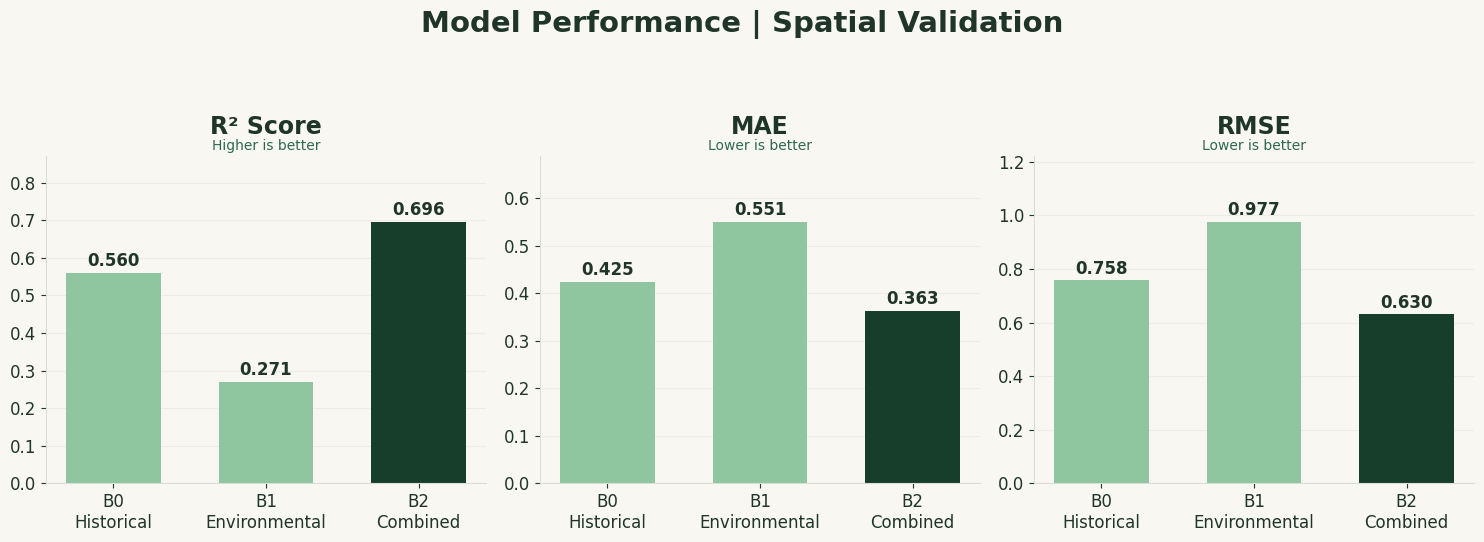

In [42]:
models = ["B0\nHistorical", "B1\nEnvironmental", "B2\nCombined"]
r2 = [0.5603, 0.2709, 0.6960]
mae = [0.4248, 0.5507, 0.3634]
rmse = [0.7583, 0.9765, 0.6305]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = [
    ("R² Score", r2, "Higher is better"),
    ("MAE", mae, "Lower is better"),
    ("RMSE", rmse, "Lower is better")
]

for ax, (title, values, direction) in zip(axes, metrics):
    colors = [LIGHT_GREEN, LIGHT_GREEN, DARK_GREEN]

    bars = ax.bar(models, values, color=colors, width=0.62)

    ax.set_title(title, fontsize=17, fontweight="bold", pad=16)
    ax.text(
        0.5, 1.02, direction,
        transform=ax.transAxes,
        ha="center", fontsize=10, color=MID_GREEN
    )

    ax.set_ylim(0, max(values) * 1.25)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + max(values)*0.025,
            f"{value:.3f}",
            ha="center", fontweight="bold"
        )

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

fig.suptitle(
    "Model Performance | Spatial Validation",
    fontsize=21, fontweight="bold", y=1.08
)

plt.tight_layout()
plt.savefig("model_performance.png", dpi=300, bbox_inches="tight")
plt.show()

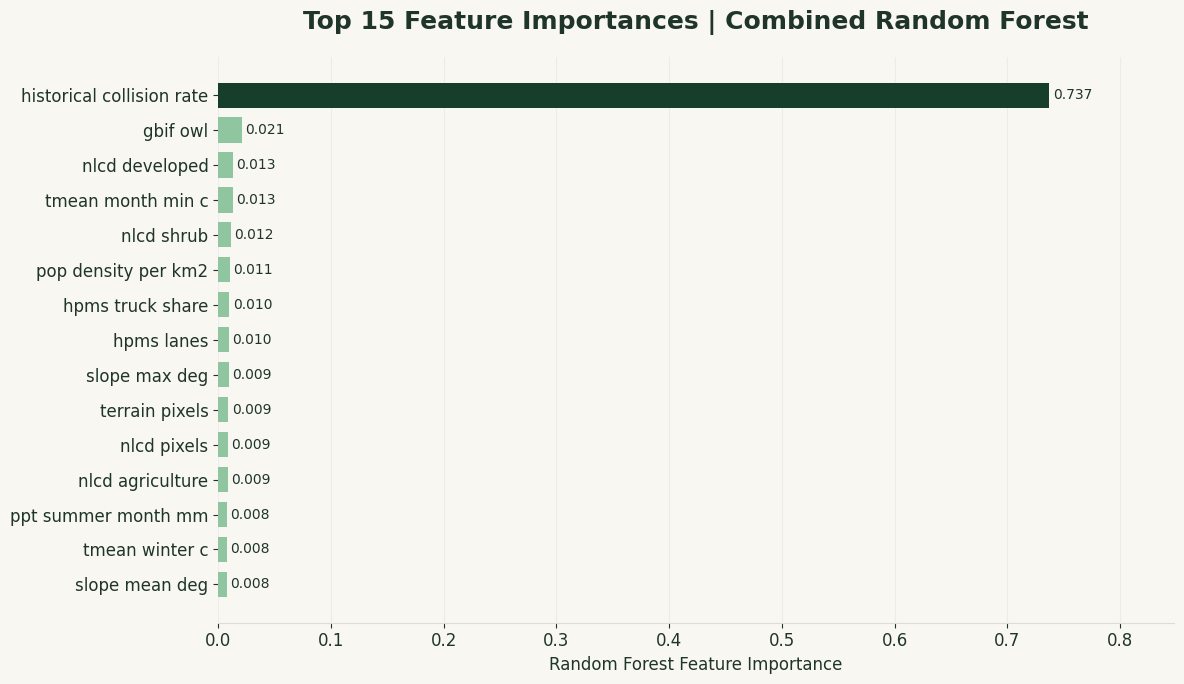

In [43]:
# Use the importance_df created earlier
top_features = importance_df.head(15).copy()

top_features["Feature"] = (
    top_features["Feature"]
    .str.replace("numeric__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
    .str.replace("_", " ")
)

top_features = top_features.sort_values("Importance")

fig, ax = plt.subplots(figsize=(12, 7))

colors = [
    DARK_GREEN if "historical collision rate" in name
    else LIGHT_GREEN
    for name in top_features["Feature"]
]

bars = ax.barh(
    top_features["Feature"],
    top_features["Importance"],
    color=colors,
    height=0.72
)

for bar, value in zip(bars, top_features["Importance"]):
    ax.text(
        value + 0.003,
        bar.get_y() + bar.get_height()/2,
        f"{value:.3f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Top 15 Feature Importances | Combined Random Forest",
    fontsize=18, fontweight="bold", pad=20
)

ax.set_xlabel("Random Forest Feature Importance")
ax.set_xlim(0, top_features["Importance"].max() * 1.15)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

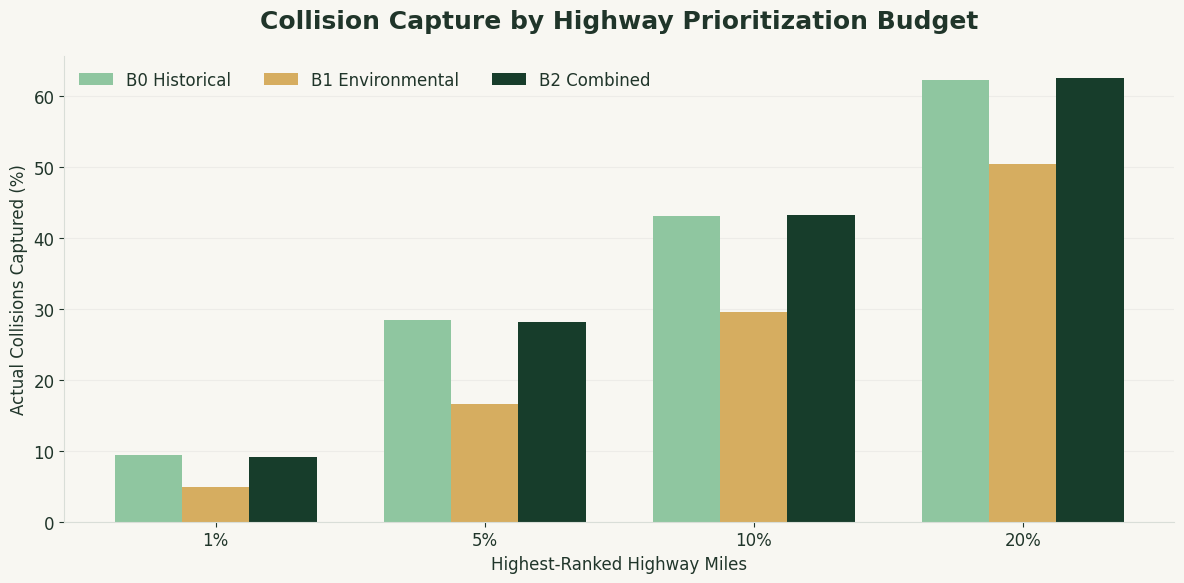

In [44]:
capture_data = pd.DataFrame({
    "Top Road Miles": ["1%", "5%", "10%", "20%"],
    "B0 Historical": [9.45, 28.38, 43.09, 62.26],
    "B1 Environmental": [4.84, 16.57, 29.50, 50.36],
    "B2 Combined": [9.12, 28.19, 43.26, 62.51]
})

x = np.arange(len(capture_data))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - width,
    capture_data["B0 Historical"],
    width,
    label="B0 Historical",
    color=LIGHT_GREEN
)

ax.bar(
    x,
    capture_data["B1 Environmental"],
    width,
    label="B1 Environmental",
    color=GOLD
)

ax.bar(
    x + width,
    capture_data["B2 Combined"],
    width,
    label="B2 Combined",
    color=DARK_GREEN
)

ax.set_xticks(x)
ax.set_xticklabels(capture_data["Top Road Miles"])

ax.set_ylabel("Actual Collisions Captured (%)")
ax.set_xlabel("Highest-Ranked Highway Miles")

ax.set_title(
    "Collision Capture by Highway Prioritization Budget",
    fontsize=18, fontweight="bold", pad=20
)

ax.legend(frameon=False, ncol=3, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("capture_at_k.png", dpi=300, bbox_inches="tight")
plt.show()

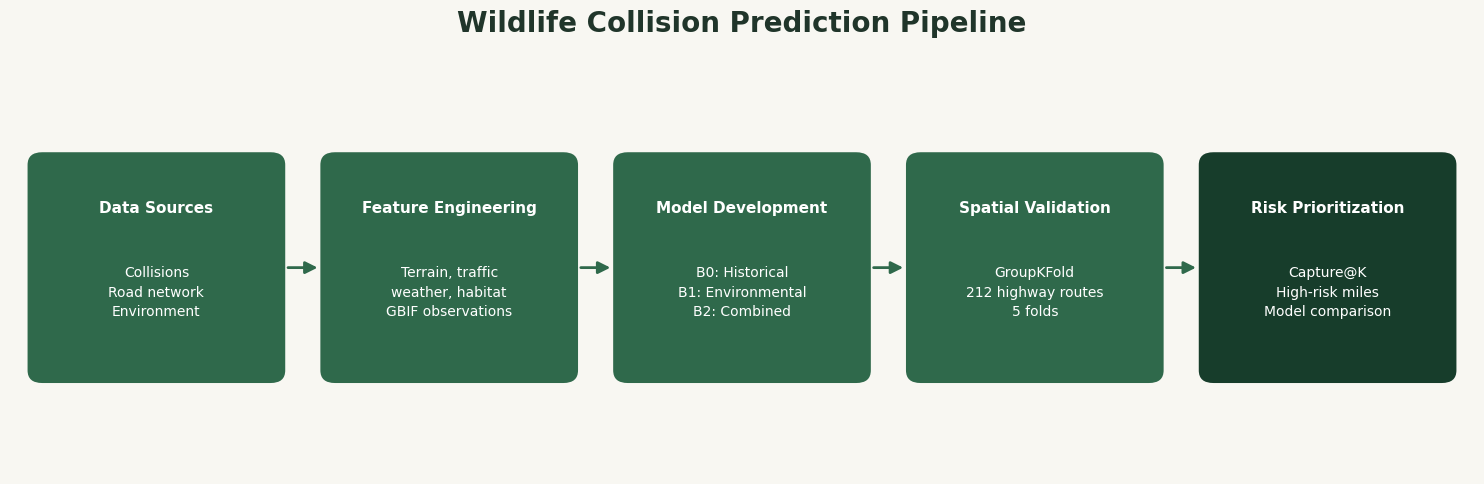

In [45]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(15, 5))
ax.set_xlim(0, 15)
ax.set_ylim(0, 5)
ax.axis("off")

steps = [
    ("Data Sources", "Collisions\nRoad network\nEnvironment"),
    ("Feature Engineering", "Terrain, traffic\nweather, habitat\nGBIF observations"),
    ("Model Development", "B0: Historical\nB1: Environmental\nB2: Combined"),
    ("Spatial Validation", "GroupKFold\n212 highway routes\n5 folds"),
    ("Risk Prioritization", "Capture@K\nHigh-risk miles\nModel comparison")
]

positions = [0.3, 3.3, 6.3, 9.3, 12.3]
box_width = 2.4
box_height = 2.5

for i, ((heading, detail), x_pos) in enumerate(zip(steps, positions)):
    color = DARK_GREEN if i == 4 else MID_GREEN

    box = FancyBboxPatch(
        (x_pos, 1.2),
        box_width,
        box_height,
        boxstyle="round,pad=0.12,rounding_size=0.15",
        facecolor=color,
        edgecolor="none"
    )
    ax.add_patch(box)

    ax.text(
        x_pos + box_width/2, 3.15,
        heading,
        ha="center", va="center",
        color=WHITE, fontsize=11, fontweight="bold"
    )

    ax.text(
        x_pos + box_width/2, 2.15,
        detail,
        ha="center", va="center",
        color=WHITE, fontsize=10,
        linespacing=1.5
    )

    if i < len(steps) - 1:
        arrow = FancyArrowPatch(
            (x_pos + box_width + 0.12, 2.45),
            (positions[i+1] - 0.12, 2.45),
            arrowstyle="-|>",
            mutation_scale=18,
            color=MID_GREEN,
            linewidth=2
        )
        ax.add_patch(arrow)

ax.set_title(
    "Wildlife Collision Prediction Pipeline",
    fontsize=20, fontweight="bold", pad=15
)

plt.tight_layout()
plt.savefig("modeling_pipeline.png", dpi=300, bbox_inches="tight")
plt.show()

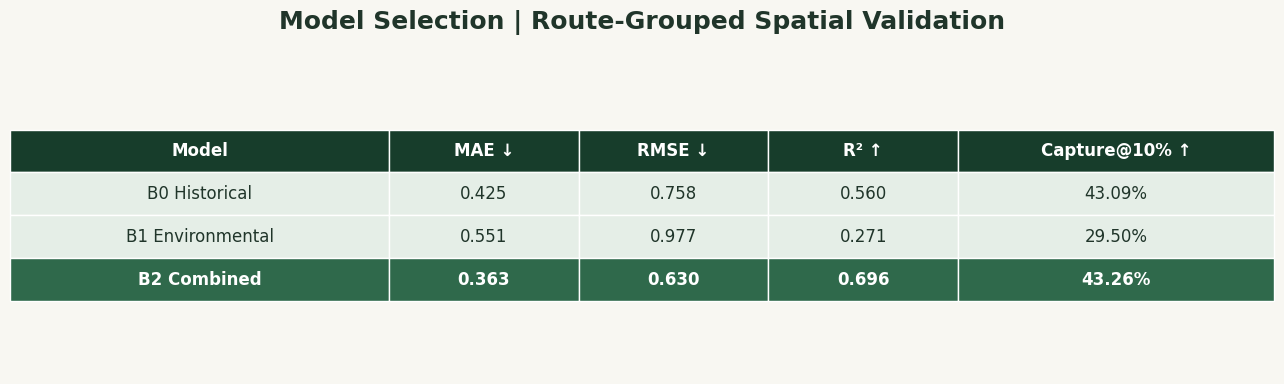

In [46]:
results = pd.DataFrame({
    "Model": ["B0 Historical", "B1 Environmental", "B2 Combined"],
    "MAE": [0.4248, 0.5507, 0.3634],
    "RMSE": [0.7583, 0.9765, 0.6305],
    "R²": [0.5603, 0.2709, 0.6960],
    "Capture@10%": ["43.09%", "29.50%", "43.26%"]
})

fig, ax = plt.subplots(figsize=(13, 4))
ax.axis("off")

cell_text = [
    [
        row["Model"],
        f'{row["MAE"]:.3f}',
        f'{row["RMSE"]:.3f}',
        f'{row["R²"]:.3f}',
        row["Capture@10%"]
    ]
    for _, row in results.iterrows()
]

table = ax.table(
    cellText=cell_text,
    colLabels=["Model", "MAE ↓", "RMSE ↓", "R² ↑", "Capture@10% ↑"],
    cellLoc="center",
    loc="center",
    colWidths=[0.30, 0.15, 0.15, 0.15, 0.25]
)

table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 2.5)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor(WHITE)

    if row == 0:
        cell.set_facecolor(DARK_GREEN)
        cell.set_text_props(color=WHITE, weight="bold")

    elif row == 3:
        cell.set_facecolor(MID_GREEN)
        cell.set_text_props(color=WHITE, weight="bold")

    else:
        cell.set_facecolor("#E5EEE7")
        cell.set_text_props(color=TEXT)

ax.set_title(
    "Model Selection | Route-Grouped Spatial Validation",
    fontsize=18, fontweight="bold", pad=20
)

plt.tight_layout()
plt.savefig("model_selection.png", dpi=300, bbox_inches="tight")
plt.show()